# w1 · Tabular models (KKBox churn)

*Three comparable non-neural tabular models (M1 logistic, M2 RandomForest,
M3 XGBoost), per-family Optuna search, one shared split, common metrics,
confusion matrices, final refit and reloadable scoring.*

The KPI is **log-loss** (probability quality). The real churn rate (~9%) is kept:
no SMOTE, no subsampling of classes, no manual rescaling of probabilities.

## Catalogue

| ID | Visible name | Input | Optimisation |
|----|--------------|-------|--------------|
| M1 | Logistic regression | Table | own Optuna |
| M2 | RandomForest | Table | own Optuna |
| M3 | XGBoost | Table | own Optuna |

## Month-over-month validation, holdout kept out of every decision

The models must predict next month's churn for users they have never been scored on, so the
evaluation reproduces that situation with two labelled monthly cohorts:

| Part | Cohort | Features known through | Label month | Use |
|---|---|---|---|---|
| `fit` / `stop` / `tune` | `train_feb` | 2017-01-31 | February | train, early stop, Optuna + threshold |
| `holdout` | `train` (March) | 2017-02-28 | March | single final evaluation |

- **development** = the whole February cohort, split once by a stable msno hash, stratified
  by label, into `fit` (~75%), `stop` (~12.5%) and `tune` (~12.5%).
- **holdout** = the whole March cohort (`train_v2`). It is a later month with its own cutoff,
  so its feature distribution (e.g. `days_to_expire`) matches what the model saw in training,
  and the gap between `tune` and `holdout` measures month-to-month drift instead of an
  artificial expiry shift. Most users appear in both months with different snapshots and labels;
  that is the production setting (the same subscriber is scored every month).

Optuna trains on `fit`, early-stops on `stop`, and reports log-loss on `tune`.
Thresholds and the winner are fixed on February **before** March is touched. Then each family
is refit on all of February and evaluated once on March. Finally the models are refit on
February + March for April inference. Test has no labels.

Churn prevalence differs between months (≈ 6.4 % in February, ≈ 9.0 % in March), so part of
the holdout gap is prevalence shift; the metrics table reports both rates.

The neural models (3 LSTM + hybrid MLP) live in the w2 neural notebook.


## 1. Configuration 
`SMOKE_TEST=True` runs a tiny sample with few trials to validate the code; its output goes
to a separate folder and is clearly marked as a test. The default (`SMOKE_TEST=False`) uses
every eligible user. Smoke results are never published as FULL.

`run_config` turns those flags into the budgets and bounds each model uses (trials per family,
boosting rounds, RandomForest caps); `run_paths` resolves where the export is read from and
where artifacts are written, on Kaggle or locally.


In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd

from xgboost import XGBClassifier
import joblib

from src.models.constants import EPS, MODEL_IDS, STUDY_TAGS
from src.models.feature_preparation.config import (
    DEV_COHORT, HOLD_COHORT, run_config, run_paths,
)
from src.models.feature_preparation.data import load_cohorts, load_metadata
from src.models.feature_preparation.environment import model_environment
from src.models.feature_preparation.split import (
    make_shared_split, validate_and_save_split,
)
from src.models.feature_preparation.tabular_prep import (
    PhasePreprocessor, make_phase_rows,
)
from src.models.baselines.logistic_regression import run_logistic
from src.models.baselines.random_forest import run_random_forest
from src.models.baselines.random_forest_data import RandomForestData
from src.models.baselines.xgboost_model import run_xgboost
from src.models.evaluation.selection import select_on_tune
from src.models.evaluation.refit import (
    fit_development_models, score_holdout,
)
from src.models.evaluation.tables import (
    DISPLAY_COLUMNS, build_holdout_tables, save_holdout_tables,
)
from src.models.evaluation.confusion import save_confusion_figures
from src.models.evaluation.reports import save_classification_reports
from src.models.evaluation.curves import (
    plot_reliability_histogram, plot_roc_pr,
)
from src.models.evaluation.optuna_history import plot_optuna_histories
from src.models.tunning.registry import Registry, SplitData
from src.models.tunning.tunning import (
    contract_hash, get_study as get_persistent_study,
    make_contract, run_study as run_persistent_study,
)

warnings.filterwarnings("ignore")
SMOKE_TEST = False
config = run_config(SMOKE_TEST)
SEED = config["seed"]
OPTUNA_MAX_TRIALS = config["optuna_max_trials"]
TRIALS = config["trials"]
TRAIN_VERBOSE = config["train_verbose"]
TREE_LOG_PERIOD = config["tree_log_period"]
XGB_BALANCED_WEIGHT = config["xgb_balanced_weight"]
TREE_MAX_ROUNDS = config["tree_max_rounds"]
TREE_EARLY_STOP = config["tree_early_stop"]
SMOKE_USERS = config["smoke_users"]
SMOKE_TEST_ROWS = config["smoke_test_rows"]
RF_N_ESTIMATORS_MAX = config["rf_n_estimators_max"]
RF_MAX_DEPTH_CAP = config["rf_max_depth_cap"]
RF_MIN_SAMPLES_LEAF_MIN = config["rf_min_samples_leaf_min"]
RF_MIN_SAMPLES_SPLIT_MIN = config["rf_min_samples_split_min"]
print("SMOKE_TEST:", SMOKE_TEST, "| trials:", TRIALS,
      "| total trials:", sum(TRIALS.values()), "| tree rounds:", TREE_MAX_ROUNDS)


SMOKE_TEST: False | trials: {'M1': 3, 'M2': 3, 'M3': 8} | total trials: 14 | tree rounds: 3000


In [5]:
ON_KAGGLE, INPUT_DIR, OUT_DIR = run_paths(SMOKE_TEST)
print("INPUT_DIR:", INPUT_DIR, "| OUT_DIR:", OUT_DIR, "| ON_KAGGLE:", ON_KAGGLE)


INPUT_DIR: export-tabular-v5 | OUT_DIR: artifacts/sherlock_w1 | ON_KAGGLE: False


## 2. Data loading 

Reads the tabular v5 export. `load_metadata` validates `dataset_version == 5` and the three
cutoffs before anything is read, and returns the feature catalogue and the categorical columns.
`load_cohorts` reads the two labelled cohorts and test, confirms each parquet's `msno` order
reproduces its published hash, and stacks the cohorts into one frame (`cohort` column: February
rows first, then March) with an explicit `row` index, so every split below is a set of row
positions in that frame.

```mermaid
flowchart LR
    meta["metadata.json<br/>version · cutoffs · features"] --> coh
    feb["train_feb.parquet"] --> coh["load_cohorts"]
    mar["train.parquet"] --> coh
    coh --> stacked["stacked train_df<br/>cohort = Feb | Mar · row index"]
    apr["test.parquet"] --> test["test_df<br/>(features only)"]
```

Both labelled months share one v5 contract; the March cohort is read one month later with its
own cutoff, not from a separate export.


In [6]:
META, FEATURES, CATEGORICAL, NUMERIC = load_metadata(INPUT_DIR)
print("dataset_version:", META["dataset_version"],
      "| features:", len(FEATURES), "| categorical:", CATEGORICAL)
print("cutoffs:", META["cutoffs"], "| label months:", META["label_months"])


dataset_version: 5 | features: 106 | categorical: ['city', 'registered_via', 'last_payment_method_id']
cutoffs: {'train_feb': '2017-01-31', 'train': '2017-02-28', 'test': '2017-03-31'} | label months: {'train_feb': '2017-02', 'train': '2017-03', 'test': '2017-04'}


In [7]:
train_df, test_df, y_all, COHORT = load_cohorts(
    INPUT_DIR, META, FEATURES, DEV_COHORT, HOLD_COHORT
)


train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
train     rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
stacked train: (1963891, 110) | test: (907471, 108) | users in both labelled months: 881701


## 3. Shared split 

One protocol for every model. The **holdout** is the whole March cohort (`train_v2` labels,
features through 2017-02-28). **Development** is the whole February cohort (`train.csv`
labels, features through 2017-01-31), split once by a stable msno hash stratified by label
into `fit` (~75 %), `stop` (~12.5 %) and `tune` (~12.5 %).

`make_shared_split` builds the parts; because the assignment uses a stable `msno` hash it is
reproducible without relying on RNG order. The optional smoke subsample (both classes kept) is
drawn inside it. `validate_and_save_split` checks the invariants and writes
`split_indices.npz` plus `split_summary.csv`.

```mermaid
flowchart TD
    feb["February cohort (development)"] --> hash["stable msno hash<br/>stratified by label"]
    hash --> fit["fit ~75 %"]
    hash --> stop["stop ~12.5 %"]
    hash --> tune["tune ~12.5 %"]
    mar["March cohort"] --> hold["holdout 100 %"]
```

These are internal parts of a single evaluation, not alternative experiments. Every model uses
the same rows in each part. The diagnostic records sizes, prevalences and the `days_to_expire`
distribution per part: with a cross-month holdout the timing features of `fit` and `holdout`
should overlap.


In [8]:
SPLIT, DEV_ROWS = make_shared_split(
    train_df, COHORT, y_all, smoke_users=SMOKE_USERS, seed=SEED,
    dev_cohort=DEV_COHORT, hold_cohort=HOLD_COHORT,
)


In [9]:
split_summary, FIT_RATE = validate_and_save_split(
    SPLIT, DEV_ROWS, train_df, COHORT, y_all, META, OUT_DIR,
    dev_cohort=DEV_COHORT, hold_cohort=HOLD_COHORT,
)
split_summary


saved split_indices.npz and split_summary.csv | fit churn rate: 0.06392


,part,cohort,label_month,n_users,churn_rate,n_churn,n_stay,days_to_expire_p01,days_to_expire_p50,days_to_expire_p99
0,fit,train_feb,2017-02,744699,0.06392,47604,697095,-6.0,17.0,56.0
1,stop,train_feb,2017-02,124117,0.06392,7934,116183,-5.0,17.0,55.0
2,tune,train_feb,2017-02,124115,0.06392,7933,116182,-6.0,17.0,56.0
3,holdout,train,2017-03,970960,0.08994,87330,883630,-7.0,18.0,61.0


## 4. Tabular transform 

The tabular preprocessor imputes (median), applies signed log1p, clips and standardises the
numeric columns, and one-hot encodes the categorical columns using the fit levels. It is fit
**only** on each phase's training rows (`fit`, all of February for the development refit, or
February + March for the final refit); categories are never unioned with test.

`make_phase_rows` maps each phase to the rows its state is fit on. `PhasePreprocessor.state(phase)`
fits and caches that state, and `PhasePreprocessor.batch(rows, phase, dataset)` transforms indexed
train or test rows with it. The tree models use native categoricals or an ordinal fit-vocabulary
(RandomForest), never the test levels.


In [10]:
PHASE_ROWS = make_phase_rows(
    SPLIT, DEV_ROWS, len(train_df), smoke_users=SMOKE_USERS
)
preprocessor = PhasePreprocessor(
    train_df, test_df, PHASE_ROWS, FEATURES, CATEGORICAL
)


## 5. Environment (environment.py)

`model_environment(SEED)` seeds the RNGs, silences Optuna's per-trial logging and detects the
XGBoost device from its CUDA build before training. It also returns the library versions stored
with the run artifacts.


In [11]:
XGB_DEVICE, ENV = model_environment(SEED)
print("Environment:", json.dumps(ENV, indent=2))
if XGB_DEVICE == "cpu":
    print("NOTE: XGBoost running on CPU (no CUDA build).")


Environment: {
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "sklearn": "1.8.0",
  "xgboost": "3.1.1",
  "optuna": "4.6.0",
  "xgb_device": "cuda"
}


## 6. Tuning: registry and Optuna studies (tunning)

Everything a model produces is book-kept by the `tunning` package, so no later section reads
training globals.

- `registry.py` — `Registry` stores, per model id, a record (family, inputs, best params,
  trial counts, timings, estimator) and the clipped probability arrays for `tune` and
  `holdout` (`register`, `set_proba`). `SplitData` exposes the shared split as row positions
  and labels (`rows(part)`, `y(part)`).
- `tunning.py` — the persistent Optuna layer. `make_contract`/`contract_hash` fingerprint the
  data, split, libraries and model settings, so a study is only resumed when the contract is
  unchanged; `get_study` creates or resumes it (TPE sampler, median pruner); `run_study` runs
  only the trials still missing from the budget, counts complete/pruned/failed trials and saves
  `*_trials.csv` and `*_best_params.json`.


In [12]:
# Shared model records, probabilities, and row access.
registry = Registry(EPS)
split_data = SplitData(SPLIT, y_all)
REGISTRY = registry.records
PROBA = registry.proba
register = registry.register
set_proba = registry.set_proba
rows_of = split_data.rows
y_of = split_data.y


In [13]:
# Persistent Optuna studies share one data/split contract.
OPTUNA_DIR = OUT_DIR / "optuna"
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
STORAGE = f"sqlite:///{(OPTUNA_DIR / 'studies.sqlite3').as_posix()}"
CONTRACT = make_contract(
    META, SPLIT, SMOKE_TEST, ENV,
    extra={
        "rf_n_estimators_max": RF_N_ESTIMATORS_MAX,
        "rf_max_depth_cap": RF_MAX_DEPTH_CAP,
        "xgb_balanced_weight": XGB_BALANCED_WEIGHT,
    },
)
CONTRACT_HASH = contract_hash(CONTRACT)


def get_study(model_id):
    return get_persistent_study(
        model_id, CONTRACT, STORAGE, SEED, TRIALS[model_id],
        tag=STUDY_TAGS.get(model_id, ""),
    )


def run_study(model_id, objective, total_trials, enqueue=None):
    return run_persistent_study(
        model_id, objective, get_study(model_id), total_trials,
        OPTUNA_DIR, enqueue=enqueue,
    )


## 7. Tabular studies (M1, M2, M3)

M1 (logistic), M2 (RandomForest) and M3 (XGBoost) each get their own Optuna study that trains
on `fit`, early-stops on `stop` (XGBoost) and reports log-loss on `tune`. Preprocessors are fit
only on the phase's training users; categories are never unioned with test. M1 uses
`newton-cholesky`, suited to the many-rows/few-features binary case here. M2 encodes
categoricals ordinally using the fit vocabulary.


In [14]:
# Development labels for all three model families.
y_fit, y_stop, y_tune = y_of("fit"), y_of("stop"), y_of("tune")


In [15]:
# M1: tune and fit logistic regression on the shared split.
run_logistic(
    train_df=train_df,
    features=FEATURES,
    numeric=NUMERIC,
    categorical=CATEGORICAL,
    split_data=split_data,
    registry=registry,
    study=get_study("M1"),
    total_trials=TRIALS["M1"],
    out_dir=OPTUNA_DIR,
    seed=SEED,
    verbose=TRAIN_VERBOSE,
    eps=EPS,
)


M1: budget=3, remaining=3


  0%|          | 0/3 [00:00<?, ?it/s]

M1: starting trial #0
Newton iter=1
  Check Convergence
    1. max |gradient| 0.095353376029603 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.02938154842494863 <= 0.0001 False
Newton iter=3
  Check Convergence
    1. max |gradient| 0.007984336801304323 <= 0.0001 False
Newton iter=4
  Check Convergence
    1. max |gradient| 0.0014064092968123325 <= 0.0001 False
Newton iter=5
  Check Convergence
    1. max |gradient| 8.405615161613533e-05 <= 0.0001 True
    2. Newton decrement 0.00010260321167780062 <= 0.0001 False
Newton iter=6
  Check Convergence
    1. max |gradient| 6.596057874263569e-07 <= 0.0001 True
    2. Newton decrement 6.135530425290649e-07 <= 0.0001 True
  Solver did converge at loss = 0.1564872031227292.
M1: trial #0 COMPLETE | log-loss=0.155545955891619 | 13.0s
M1: starting trial #1
Newton iter=1
  Check Convergence
    1. max |gradient| 0.09535329204987483 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.0293815937758047

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spar

In [16]:
# Shared categorical encoding for the tree models: use the fit vocabulary only,
# so unseen levels in other parts/test become missing (XGBoost handles NaN).
_tree_vocab = {}


def tree_vocab(phase):
    if phase not in _tree_vocab:
        rows = PHASE_ROWS[phase]
        _tree_vocab[phase] = {
            c: sorted(pd.unique(train_df[c].iloc[rows].dropna()).tolist())
            for c in CATEGORICAL
        }
    return _tree_vocab[phase]


def tree_frame(rows, phase, dataset="train", vocab=None):
    frame = (
        train_df if dataset == "train" else test_df
    ).iloc[np.asarray(rows)][FEATURES].copy()
    vocab = vocab or tree_vocab(phase)
    for col in CATEGORICAL:
        frame[col] = pd.Categorical(frame[col], categories=vocab[col])
    return frame


In [17]:
# M2: RandomForest keeps a training-only vocabulary for each phase.
rf_data = RandomForestData(
    train_df, test_df, PHASE_ROWS, FEATURES, CATEGORICAL
)
run_random_forest(
    data=rf_data,
    split_data=split_data,
    registry=registry,
    study=get_study("M2"),
    total_trials=TRIALS["M2"],
    out_dir=OPTUNA_DIR,
    seed=SEED,
    eps=EPS,
)


M2: budget=3, remaining=3


  0%|          | 0/3 [00:00<?, ?it/s]

M2: starting trial #0
M2: trial #0 COMPLETE | log-loss=0.14596004145390984 | 81.0s
M2: starting trial #1
M2: trial #1 COMPLETE | log-loss=0.145933683201758 | 81.0s
M2: starting trial #2
M2: trial #2 COMPLETE | log-loss=0.14611649980266164 | 68.3s
M2: best tune log-loss=0.14593 | trials {'complete': 3, 'pruned': 0, 'failed': 0}
M2 best params: {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 14, 'max_features': 'sqrt'}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",14
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

In [18]:
# M3: XGBoost uses the shared phase-aware tree_frame.
run_xgboost(
    tree_frame=tree_frame,
    split_data=split_data,
    registry=registry,
    study=get_study("M3"),
    total_trials=TRIALS["M3"],
    out_dir=OPTUNA_DIR,
    device=XGB_DEVICE,
    max_rounds=TREE_MAX_ROUNDS,
    early_stop=TREE_EARLY_STOP,
    log_period=TREE_LOG_PERIOD,
    seed=SEED,
    balanced=XGB_BALANCED_WEIGHT,
    eps=EPS,
)


M3: budget=8, remaining=8


  0%|          | 0/8 [00:00<?, ?it/s]

M3: starting trial #0
[0]	validation_0-logloss:0.67222


sh: línea 1: nvidia-smi: orden no encontrada


[100]	validation_0-logloss:0.37521
[200]	validation_0-logloss:0.36707
[300]	validation_0-logloss:0.36128
[400]	validation_0-logloss:0.35562
[500]	validation_0-logloss:0.35039
[600]	validation_0-logloss:0.34572
[700]	validation_0-logloss:0.34114
[800]	validation_0-logloss:0.33645
[900]	validation_0-logloss:0.33209
[1000]	validation_0-logloss:0.32775
[1100]	validation_0-logloss:0.32372
[1200]	validation_0-logloss:0.31981
[1300]	validation_0-logloss:0.31618
[1400]	validation_0-logloss:0.31231
[1500]	validation_0-logloss:0.30874
[1600]	validation_0-logloss:0.30544
[1700]	validation_0-logloss:0.30216
[1800]	validation_0-logloss:0.29877
[1900]	validation_0-logloss:0.29595
[2000]	validation_0-logloss:0.29300
[2100]	validation_0-logloss:0.29016
[2200]	validation_0-logloss:0.28742
[2300]	validation_0-logloss:0.28487
[2400]	validation_0-logloss:0.28227
[2500]	validation_0-logloss:0.27964
[2600]	validation_0-logloss:0.27705
[2700]	validation_0-logloss:0.27477
[2800]	validation_0-logloss:0.27261
[

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8420793113166193
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import 

## 8. Thresholds, development refit and the single holdout evaluation

Thresholds come from maximum churn F1 on **tune** (February, deterministic tie rule). The
winner is chosen by tune log-loss and written to a manifest **before** the March holdout is
touched. Each trainable family is refit on all of February (preprocessors refit on February
only) and evaluated once on March. Thresholds are not re-searched on March; how a February
threshold behaves one month later is part of the honest report.


In [19]:
# Freeze thresholds and winner using February tune predictions only.
THRESHOLDS, SELECTION, primary_winner = select_on_tune(
    y_tune, registry, CONTRACT_HASH, OUT_DIR
)


primary winner (tune): M2
thresholds: {'M1': 0.26, 'M2': 0.26, 'M3': 0.69}


In [20]:
# Refit on February, then evaluate once on the March holdout.
DEV_MODELS = fit_development_models(
    train_df=train_df,
    features=FEATURES,
    numeric=NUMERIC,
    categorical=CATEGORICAL,
    dev_rows=DEV_ROWS,
    split_data=split_data,
    registry=registry,
    tree_frame=tree_frame,
    rf_data=rf_data,
    seed=SEED,
    train_verbose=TRAIN_VERBOSE,
    xgb_device=XGB_DEVICE,
    xgb_balanced_weight=XGB_BALANCED_WEIGHT,
)
y_hold, HOLD_PROBA = score_holdout(
    models=DEV_MODELS,
    train_df=train_df,
    features=FEATURES,
    split_data=split_data,
    registry=registry,
    tree_frame=tree_frame,
    rf_data=rf_data,
    selection_manifest=OUT_DIR / "selection_manifest.json",
)


Newton iter=1
  Check Convergence
    1. max |gradient| 0.09537305077980814 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.029399499675351683 <= 0.0001 False
Newton iter=3
  Check Convergence
    1. max |gradient| 0.00800596437435766 <= 0.0001 False
Newton iter=4
  Check Convergence
    1. max |gradient| 0.0014235082068626767 <= 0.0001 False
Newton iter=5
  Check Convergence
    1. max |gradient| 8.798224564133747e-05 <= 0.0001 True
    2. Newton decrement 0.0001076401346501562 <= 0.0001 False
Newton iter=6
  Check Convergence
    1. max |gradient| 1.1627193212276227e-06 <= 0.0001 True
    2. Newton decrement 9.238067506163476e-07 <= 0.0001 True
  Solver did converge at loss = 0.15620395438483548.
holdout probabilities ready for all tabular models


## 9. Metrics tables, confusion matrices and curves

Holdout (March) metrics for all tabular models at their tune (February) threshold, plus a complementary table
at threshold 0.5. Confusion matrices (counts + row-normalised) per model and as a paginated
gallery. ROC/PR curves, reliability diagrams and Optuna histories. Order
the display table by holdout log-loss for inspection, distinct from the winner fixed earlier
on tune.


In [21]:
# Metrics and per-model classification reports.
holdout_metrics, holdout_metrics_at_05 = build_holdout_tables(
    y_tune, y_hold, registry, THRESHOLDS, SELECTION
)
save_holdout_tables(holdout_metrics, holdout_metrics_at_05, OUT_DIR)
REPORT_DIR = save_classification_reports(y_hold, registry, THRESHOLDS, OUT_DIR)
FIG_DIR = OUT_DIR / "figures"
print("Holdout = March cohort; tune = February. Prevalence tune/holdout:",
      round(float(y_tune.mean()), 4), "/", round(float(y_hold.mean()), 4))
print("Holdout metrics ordered by log-loss (winner fixed on tune:",
      primary_winner, ")")
holdout_metrics[DISPLAY_COLUMNS].round(5)


Holdout = March cohort; tune = February. Prevalence tune/holdout: 0.0639 / 0.0899
Holdout metrics ordered by log-loss (winner fixed on tune: M2 )


,model_id,family,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,M2,randomforest,0.14593,0.20382,0.86068,0.59016,0.05509,0.93117,0.75188,0.64112,0.53326,0.97050,0.58224,0.77237,0.54783,0.26
1,M1,logistic,0.15535,0.21322,0.84434,0.55551,0.05654,0.92175,0.75353,0.56725,0.54840,0.95865,0.55767,0.75737,0.51485,0.26
2,M3,xgboost,0.20351,0.25086,0.82464,0.55598,0.06704,0.93056,0.71465,0.66890,0.45139,0.97792,0.53903,0.75074,0.51440,0.69


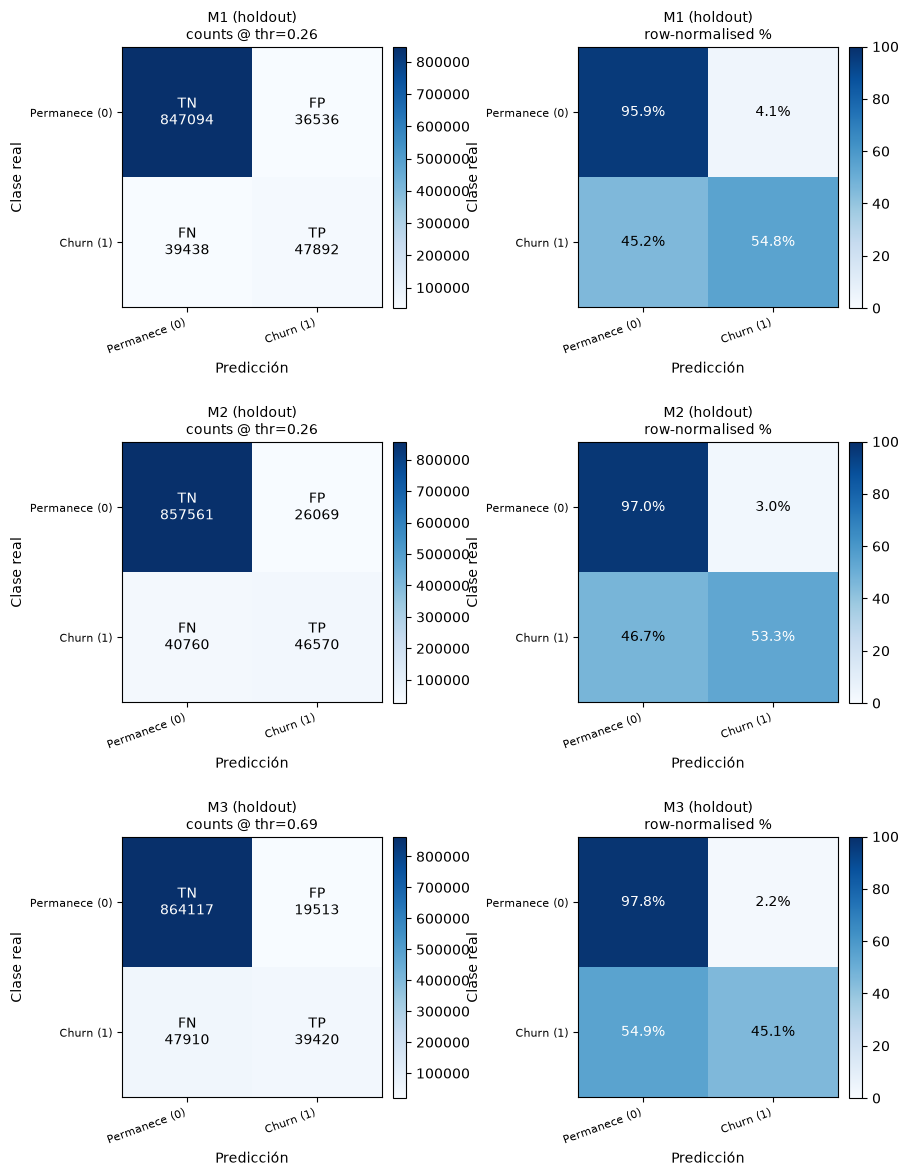

saved per-model confusion images (PNG+SVG) and gallery pages


PosixPath('artifacts/sherlock_w1/figures/confusion')

In [22]:
save_confusion_figures(y_hold, registry, THRESHOLDS, OUT_DIR)


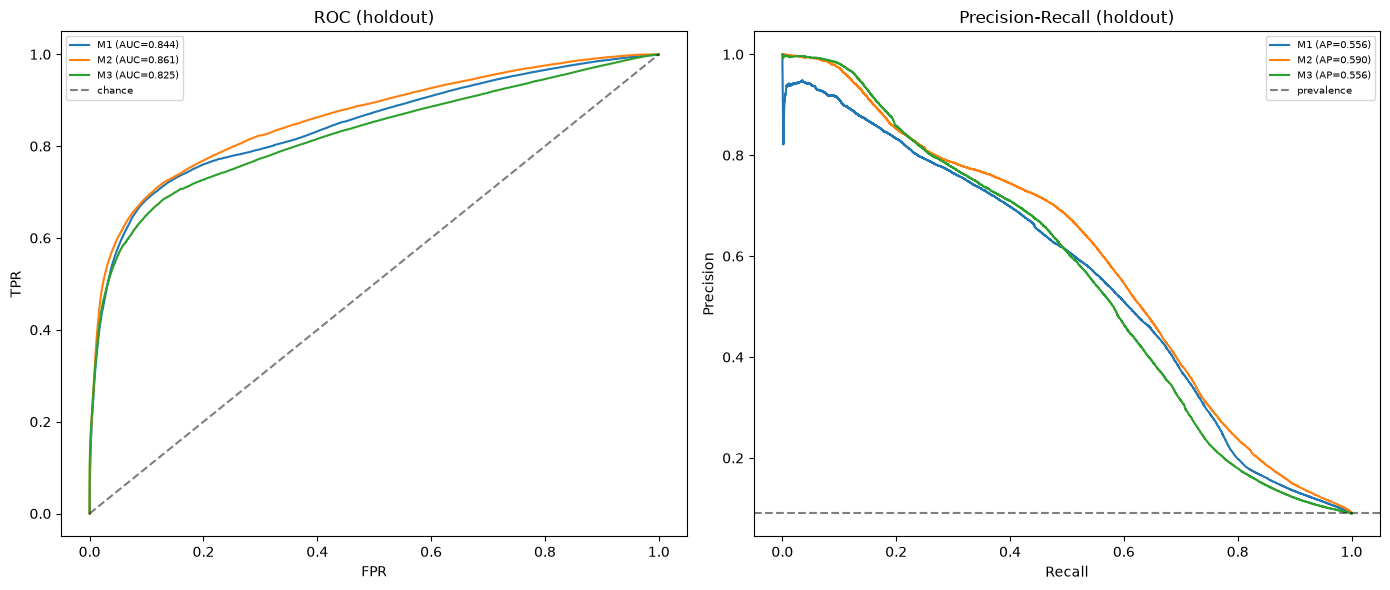

PosixPath('artifacts/sherlock_w1/figures/curves/roc_pr.png')

In [23]:
plot_roc_pr(y_hold, registry, OUT_DIR)


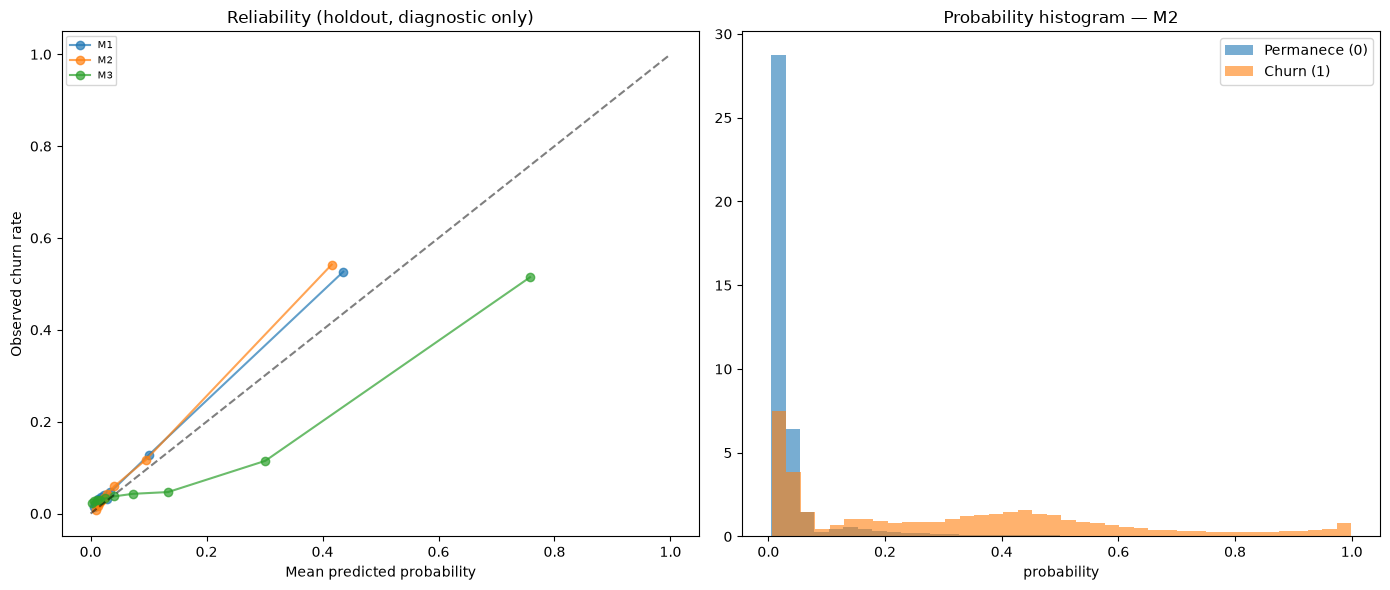

NOTE: reliability curves are diagnostics; no calibration was applied.


PosixPath('artifacts/sherlock_w1/figures/curves/calibration_hist.png')

In [24]:
plot_reliability_histogram(y_hold, registry, primary_winner, OUT_DIR)


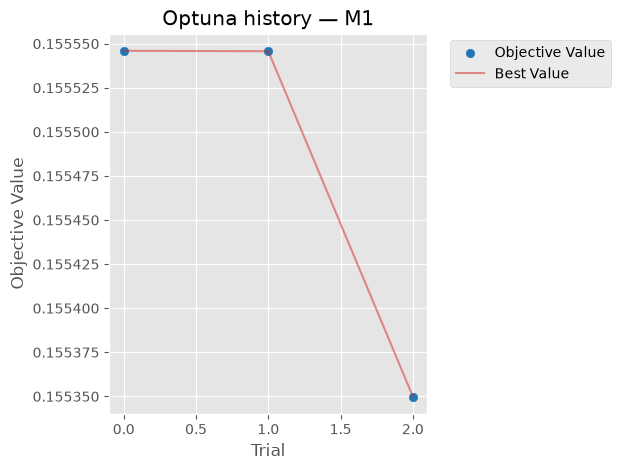

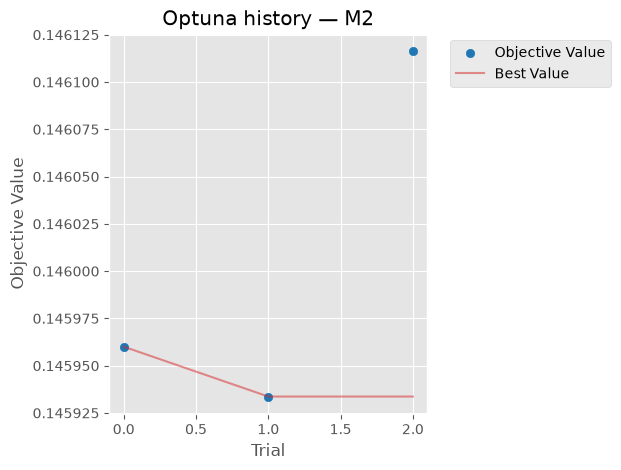

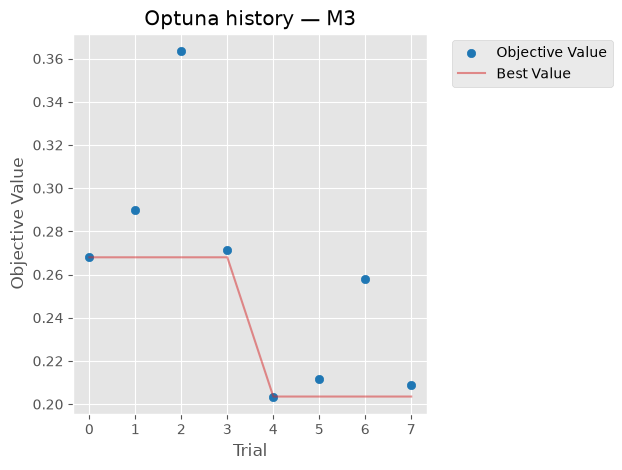

In [25]:
plot_optuna_histories(get_study)
